# Bab 6 - Membangun Jaringan Saraf Dalam Pertama Anda: Pengenalan Backpropagation

**Buku:** *Grokking Deep Learning* (Andrew W. Trask, Manning)

## Ringkasan bab
Bab ini membangun jaringan yang dapat mempelajari pola yang **tidak dapat** dipelajari oleh satu layer tunggal, dan memperkenalkan backpropagation.

1. **Masalah lampu lalu lintas (the streetlight problem):** memutuskan untuk jalan (*walk*) atau berhenti (*stop*) dari pola tiga lampu (dataset kecil yang digunakan untuk membangun ide).
2. **Menyiapkan data** sebagai matriks: input `(4, 3)` dan target `(4, 1)`; **full / batch gradient descent di seluruh dataset**.
3. **Korelasi:** jaringan tanpa hidden layer hanya mempelajari korelasi *langsung* antara setiap input dan output.
4. **Masalah non-linearitas:** jika jawaban yang benar bergantung pada *kombinasi* input (misalnya pola seperti XOR), jaringan **dua layer** akan gagal.
5. **Hidden layer dengan non-linearitas (ReLU):** `relu(x) = max(0, x)`. Tanpa itu, layer yang ditumpuk hanya menjadi satu layer linear.
6. **Backpropagation:** hitung output delta dan teruskan secara *mundur (backward)* melalui jaringan untuk mendapatkan delta pada setiap layer: `layer_1_delta = layer_2_delta . W2^T * relu2deriv(layer_1)`.
7. Jaringan **tiga layer** penuh yang dilatih dengan gradient descent yang kini menyelesaikan masalah tersebut.

## Teori secara mendalam

### Korelasi dan jaringan 2-layer
Jaringan yang hanya memiliki input layer dan output layer menetapkan bobot untuk setiap input. Jika suatu input, secara mandiri, naik dan turun bersamaan dengan target, bobotnya akan naik.
Jika input tidak memiliki korelasi *langsung* dengan target, bobotnya menjadi nol. Oleh karena itu jaringan semacam itu hanya dapat menemukan hubungan **linear**.

### Pola bergaya XOR
Andaikan target bernilai 1 ketika tepat satu dari dua lampu menyala, tetapi 0 ketika keduanya menyala atau keduanya padam. Tidak ada lampu yang berkorelasi dengan target secara individu
(masing-masing menyala pada separuh kasus "jalan" dan separuh kasus "berhenti"), sehingga tidak ada bobot yang dapat mengurangi error. Solusinya membutuhkan **layer perantara (intermediate layer)** yang dapat membangun
fitur baru seperti "lampu kiri menyala DAN lampu kanan padam".

### Mengapa non-linearitas diperlukan
`hidden = x W1` dan `pred = hidden W2` menyusut menjadi `pred = x (W1 W2)`, yaitu satu pemetaan linear tunggal. Fungsi non-linear di antara layer (di sini ReLU) memecah penyusutan tersebut
dan memungkinkan hidden layer untuk "berkorelasi secara selektif" dengan input: node hidden menyala hanya ketika input berbobotnya bernilai positif.

### Backpropagation
Gradient descent membutuhkan `delta` untuk setiap bobot. Untuk layer terakhir, nilainya adalah `pred - goal`. Untuk hidden layer kita bertanya: *seberapa besar kontribusi setiap node hidden terhadap error akhir?* Jawabannya
adalah dengan mengirimkan output delta secara **mundur** melalui bobot yang menghubungkannya (`layer_2_delta . W2^T`), dan mengalikannya dengan turunan dari non-linearitas (0 di mana ReLU padam, 1 di mana ReLU menyala),
sehingga node yang padam tidak menerima kesalahan. Kemudian `W = W - alpha * layer_input^T . layer_delta`.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
np.random.seed(1)

## 1. Data
Setiap baris adalah keadaan tiga lampu lalu lintas (1 = menyala). Target menyatakan apakah aman untuk jalan (1) atau berhenti (0). Di sini jawabannya bergantung pada *kombinasi* dua lampu pertama
(jalan ketika tepat satu dari keduanya menyala), yang tidak dapat ditangkap oleh jaringan satu layer.

In [2]:
streetlights = np.array([[1, 0, 1],
                         [0, 1, 1],
                         [0, 0, 1],
                         [1, 1, 1]])
walk_vs_stop = np.array([[1, 1, 0, 0]]).T
print(streetlights.shape, walk_vs_stop.shape)

(4, 3) (4, 1)


## 2. Jaringan dua layer (tanpa hidden layer) tidak dapat mempelajarinya

In [3]:
weights = 2 * np.random.random((3, 1)) - 1
alpha = 0.1
errs2 = []
for it in range(60):
    pred = streetlights.dot(weights)
    delta = pred - walk_vs_stop
    errs2.append(np.sum(delta ** 2))
    weights -= alpha * streetlights.T.dot(delta)
print('final error of the 2-layer network:', round(errs2[-1], 4))
print('predictions:', np.round(streetlights.dot(weights).ravel(), 3), ' targets:', walk_vs_stop.ravel())

final error of the 2-layer network: 1.0004
predictions: [0.497 0.498 0.485 0.51 ]  targets: [1 1 0 0]


Error mengendap di sekitar 1.0 (tidak pernah mendekati 0), dan prediksi tertahan di dekat 0.5 untuk setiap baris. Tidak ada himpunan bobot yang cocok dengan data karena jawabannya bukan fungsi linear dari input.

## 3. Jaringan tiga layer dengan ReLU dan backpropagation

In [4]:
def relu(x):
    return (x > 0) * x          # mengembalikan x jika x > 0, jika tidak 0

def relu2deriv(output):
    return output > 0           # turunan: 1 jika node aktif, 0 jika padam

np.random.seed(1)
alpha = 0.2
hidden_size = 4

weights_0_1 = 2 * np.random.random((3, hidden_size)) - 1
weights_1_2 = 2 * np.random.random((hidden_size, 1)) - 1

errs3 = []
for it in range(60):
    layer_2_error = 0
    for i in range(len(streetlights)):
        layer_0 = streetlights[i:i + 1]
        layer_1 = relu(layer_0.dot(weights_0_1))       # forward: hidden layer
        layer_2 = layer_1.dot(weights_1_2)             # forward: output

        layer_2_error += np.sum((layer_2 - walk_vs_stop[i:i + 1]) ** 2)

        layer_2_delta = layer_2 - walk_vs_stop[i:i + 1]                         # output delta
        layer_1_delta = layer_2_delta.dot(weights_1_2.T) * relu2deriv(layer_1)  # backpropagation

        weights_1_2 -= alpha * layer_1.T.dot(layer_2_delta)
        weights_0_1 -= alpha * layer_0.T.dot(layer_1_delta)
    errs3.append(layer_2_error)
    if it % 10 == 9:
        print(f'iteration {it + 1:2d}  error = {layer_2_error:.6f}')

iteration 10  error = 0.634231
iteration 20  error = 0.358384
iteration 30  error = 0.083018
iteration 40  error = 0.006467
iteration 50  error = 0.000329
iteration 60  error = 0.000015


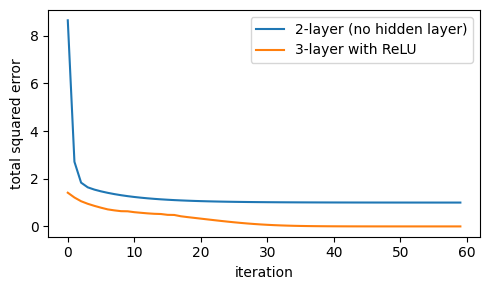

[1 0 1] -> [1.]  target [1]
[0 1 1] -> [0.999]  target [1]
[0 0 1] -> [0.003]  target [0]
[1 1 1] -> [0.]  target [0]


In [5]:
plt.figure(figsize=(5, 3))
plt.plot(errs2, label='2-layer (no hidden layer)'); plt.plot(errs3, label='3-layer with ReLU')
plt.xlabel('iteration'); plt.ylabel('total squared error'); plt.legend()
plt.tight_layout(); plt.show()

for i in range(4):
    l1 = relu(streetlights[i:i + 1].dot(weights_0_1))
    print(streetlights[i], '->', np.round(l1.dot(weights_1_2).ravel(), 3), ' target', walk_vs_stop[i])

Jaringan tiga layer mendesak error hingga hampir nol dan membuat keempat prediksi benar, karena hidden layer-nya membuat fitur baru yang *berkorelasi* dengan target. Node hidden juga menjadi
"berkorelasi secara selektif" dengan bagian dari input berkat ReLU yang memadamkannya untuk beberapa pola.

## 4. Melihat ke dalam hidden layer

In [6]:
print('hidden layer activations for each input (rows) and hidden node (columns):')
print(np.round(relu(streetlights.dot(weights_0_1)), 2))

hidden layer activations for each input (rows) and hidden node (columns):
[[-0.    0.88 -0.   -0.  ]
 [-0.   -0.   -0.    0.9 ]
 [-0.   -0.   -0.    0.  ]
 [-0.   -0.   -0.   -0.  ]]


Hanya dua node hidden yang pernah aktif: satu menyala hanya untuk `[1, 0, 1]` dan yang lain hanya untuk `[0, 1, 1]`, yaitu dua pola "jalan". Untuk `[0, 0, 1]` dan `[1, 1, 1]` setiap node hidden dipadamkan oleh ReLU, sehingga output bernilai sekitar 0 ("berhenti"). Oleh karena itu hidden layer telah belajar untuk *mendeteksi* dua pola yang berarti "jalan", sebuah kombinasi lampu yang tidak dapat disinyalkan oleh lampu tunggal mana pun.

## Poin-poin kunci
* Jaringan tanpa hidden layer hanya dapat mempelajari korelasi langsung (linear).
* Hidden layer + aktivasi non-linear (ReLU) memungkinkan jaringan untuk membuat fitur perantara dan menyelesaikan masalah non-linear.
* Backpropagation mengirimkan error output ke belakang untuk memberi setiap layer delta-nya sendiri, kemudian setiap matriks bobot diperbarui dengan `layer_input.T.dot(layer_delta)`.